<a href="https://colab.research.google.com/github/yusuf8886147/GROUP-67-_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Colab ve GitHub baglantisi kuruldu!")

Colab ve GitHub baglantisi kuruldu!


In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"yusufemnacar","key":"50b0b2e17eeaa9e7a4d3da8cd57a33fa"}'}

In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Doğru yarışma adıyla indirme işlemi
!kaggle competitions download -c neurips-open-polymer-prediction-2025

# İnen doğru ZIP dosyasını klasöre çıkart
!unzip -q neurips-open-polymer-prediction-2025.zip -d data
print("Veriler başarıyla 'data' klasörüne indirildi ve çıkartıldı!")

100% 274k/274k [00:00<00:00, 127MB/s]

Veriler başarıyla 'data' klasörüne indirildi ve çıkartıldı!


In [6]:
!mkdir -p src

In [7]:
%%writefile src/data.py
import pandas as pd
import os

def load_data(data_path="data/train.csv"):
    """
    Belirtilen yoldaki CSV dosyasını okur ve Pandas DataFrame olarak döndürür.
    """
    if os.path.exists(data_path):
        df = pd.read_csv(data_path)
        print(f"Veri başarıyla yüklendi! Boyut: {df.shape}")
        return df
    else:
        print(f"Hata: {data_path} dosyası bulunamadı. Lütfen verilerin indirildiğinden emin olun.")
        return None

Writing src/data.py


In [8]:
# src klasöründeki data.py dosyasından load_data fonksiyonumuzu projemize dahil ediyoruz
from src.data import load_data

# Fonksiyonu kullanarak veriyi train_df değişkenine atıyoruz
train_df = load_data()

# Verinin ilk 5 satırına göz atalım
train_df.head()

Veri başarıyla yüklendi! Boyut: (7973, 7)


,id,SMILES,Tg,FFV,Tc,Density,Rg
0,87817,*CC(*)c1ccccc1C(=O)OCCCCCC,NaN,0.374645,0.205667,NaN,NaN
1,106919,*Nc1ccc([C@H](CCC)c2ccc(C3(c4ccc([C@@H](CCC)c5...,NaN,0.370410,NaN,NaN,NaN
2,388772,*Oc1ccc(S(=O)(=O)c2ccc(Oc3ccc(C4(c5ccc(Oc6ccc(...,NaN,0.378860,NaN,NaN,NaN
3,519416,*Nc1ccc(-c2c(-c3ccc(C)cc3)c(-c3ccc(C)cc3)c(N*)...,NaN,0.387324,NaN,NaN,NaN
4,539187,*Oc1ccc(OC(=O)c2cc(OCCCCCCCCCOCC3CCCN3c3ccc([N...,NaN,0.355470,NaN,NaN,NaN


In [9]:
%%writefile src/utils.py
import matplotlib.pyplot as plt
import seaborn as sns

def plot_target_distributions(df):
    """
    Veri setindeki ana hedeflerin (Tg ve Tc) dağılım grafiklerini çizer.
    """
    plt.figure(figsize=(12, 5))

    # Tg Dağılımı
    plt.subplot(1, 2, 1)
    sns.histplot(df['Tg'].dropna(), kde=True, color='blue', bins=30)
    plt.title('Tg (Glass Transition Temp) Dağılımı')
    plt.xlabel('Tg Değeri')

    # Tc Dağılımı
    plt.subplot(1, 2, 2)
    sns.histplot(df['Tc'].dropna(), kde=True, color='red', bins=30)
    plt.title('Tc (Melting Temp) Dağılımı')
    plt.xlabel('Tc Değeri')

    plt.tight_layout()
    plt.show()

def plot_correlation_heatmap(df):
    """
    Sayısal değişkenler arasındaki korelasyon matrisini ısı haritası olarak çizer.
    """
    plt.figure(figsize=(8, 6))
    # Sadece sayısal sütunları seç (SMILES metin olduğu için korelasyona giremez)
    numeric_df = df.select_dtypes(include=['float64', 'int64'])

    # Korelasyon matrisini hesapla ve çiz
    correlation_matrix = numeric_df.corr()
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Sayısal Değişkenler Arası Korelasyon Isı Haritası')
    plt.show()

Writing src/utils.py


--- Polimer Özelliklerinin Dağılım Analizi ---


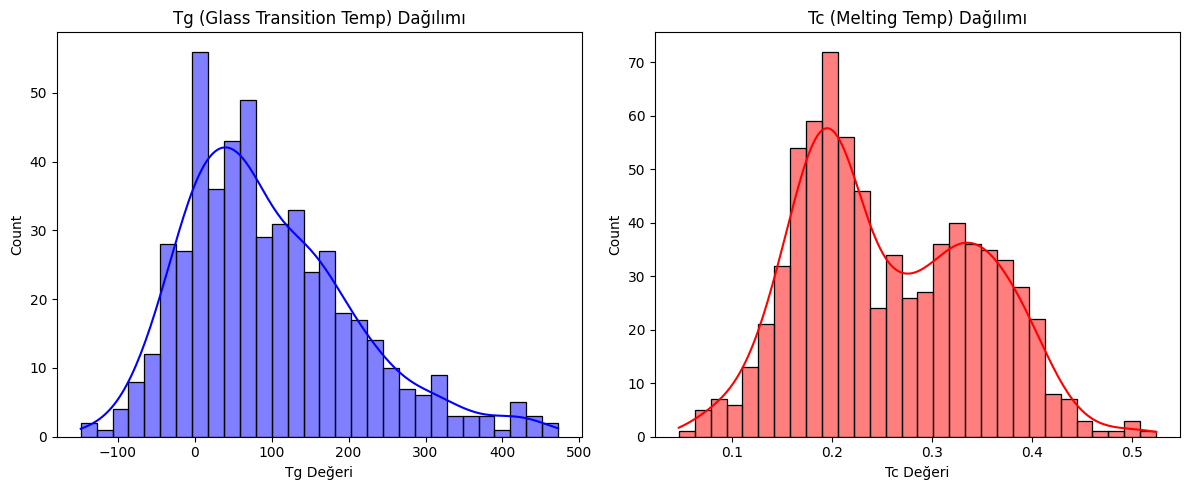


--- Sayısal Değişkenler Arası İlişkiler ---


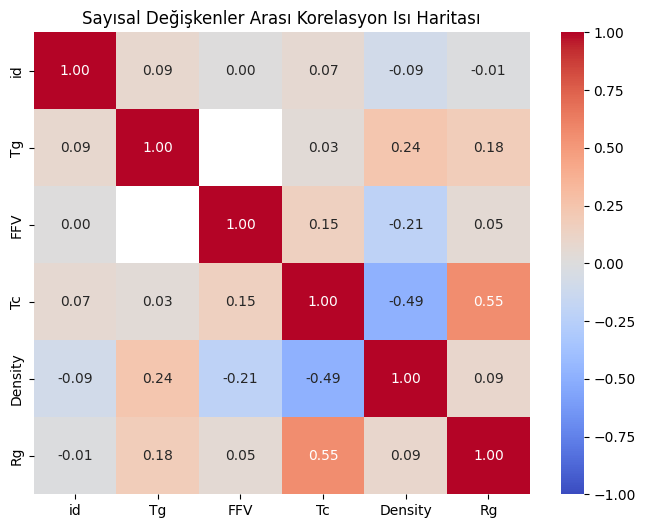

In [10]:
# utils.py modülümüzden grafik fonksiyonlarını içe aktarıyoruz
from src.utils import plot_target_distributions, plot_correlation_heatmap

# 1. Hedef değişkenlerin dağılım grafiklerini çizdir
print("--- Polimer Özelliklerinin Dağılım Analizi ---")
plot_target_distributions(train_df)

# 2. Değişkenler arası ilişkileri (korelasyon) ısı haritasıyla incele
print("\n--- Sayısal Değişkenler Arası İlişkiler ---")
plot_correlation_heatmap(train_df)

In [11]:
%%writefile src/utils.py
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_target_distributions(df):
    """Hedeflerin (Tg ve Tc) dağılım grafiklerini çizer."""
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(df['Tg'].dropna(), kde=True, color='blue', bins=30)
    plt.title('Tg (Glass Transition Temp) Dağılımı')

    plt.subplot(1, 2, 2)
    sns.histplot(df['Tc'].dropna(), kde=True, color='red', bins=30)
    plt.title('Tc (Melting Temp) Dağılımı')

    plt.tight_layout()
    plt.show()

def plot_correlation_heatmap(df):
    """Sayısal değişkenler arası korelasyonu çizer."""
    plt.figure(figsize=(8, 6))
    numeric_df = df.select_dtypes(include=['float64', 'int64'])
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Sayısal Değişkenler Korelasyon Haritası')
    plt.show()

def analyze_missing_values(df):
    """Verisetindeki eksik değerlerin sayısını ve yüzdesini raporlar."""
    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Eksik_Sayisi': missing, 'Yuzde(%)': missing_percent})
    missing_df = missing_df[missing_df['Eksik_Sayisi'] > 0].sort_values(by='Yuzde(%)', ascending=False)

    print("\n--- Eksik Veri Analizi ---")
    if missing_df.empty:
        print("Verisetinde eksik değer bulunmamaktadır.")
    else:
        print(missing_df)

def plot_boxplots(df):
    """Sayısal sütunlardaki aykırı değerleri (outliers) görmek için kutu grafiği çizer."""
    plt.figure(figsize=(12, 6))
    numeric_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=['id'], errors='ignore')
    sns.boxplot(data=numeric_df, orient='h')
    plt.title('Sayısal Değişkenler Aykırı Değer (Outlier) Analizi')
    plt.show()

Overwriting src/utils.py



--- Eksik Veri Analizi ---
         Eksik_Sayisi   Yuzde(%)
Tg               7462  93.590869
Density          7360  92.311551
Rg               7359  92.299009
Tc               7236  90.756303
FFV               943  11.827418


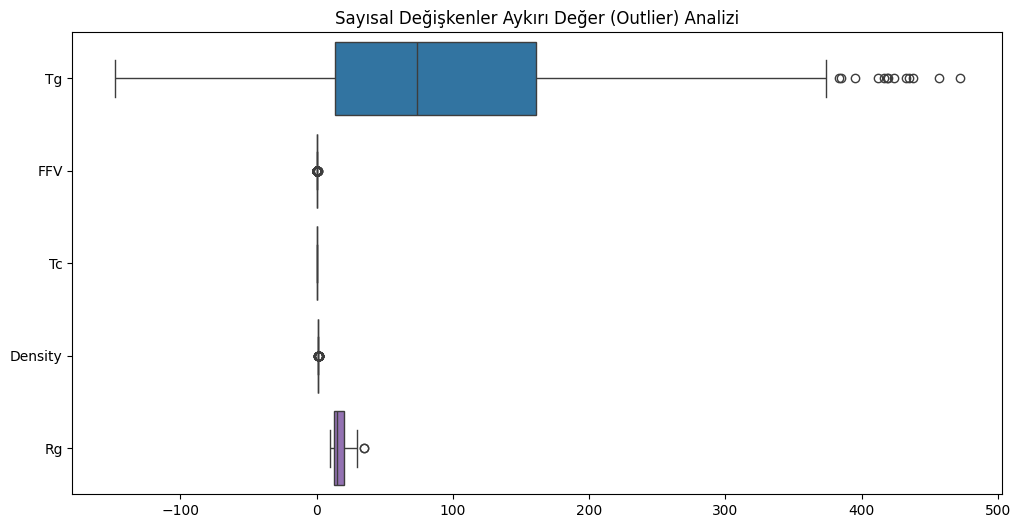

In [14]:
import sys

# Colab'in sihirli komutu yerine doğrudan Python hafızasından eski dosyayı siliyoruz
if 'src.utils' in sys.modules:
    del sys.modules['src.utils']

# Güncellenmiş utils dosyasından yeni fonksiyonları çekiyoruz
from src.utils import analyze_missing_values, plot_boxplots

# 1. Eksik veri tablosunu yazdır
analyze_missing_values(train_df)

# 2. Aykırı değerleri tespit etmek için kutu grafiklerini çiz
plot_boxplots(train_df)

In [15]:
%%writefile src/data.py
import pandas as pd
import os

def load_data(data_path="data/train.csv"):
    """Belirtilen yoldaki CSV dosyasını okur."""
    if os.path.exists(data_path):
        df = pd.read_csv(data_path)
        print(f"Veri başarıyla yüklendi! Boyut: {df.shape}")
        return df
    else:
        print(f"Hata: {data_path} dosyası bulunamadı.")
        return None

def preprocess_data(df):
    """
    Eksik verileri doldurur ve makine öğrenmesi için temel ön işleme yapar.
    Aykırı değerler (outliers) olduğu için eksikler MEDYAN ile doldurulur.
    """
    df_processed = df.copy()

    # Sadece sayısal sütunları seç
    numeric_cols = df_processed.select_dtypes(include=['float64', 'int64']).columns

    for col in numeric_cols:
        if col != 'id':  # id sütununu doldurmaya gerek yok
            # Her sütundaki boşlukları (NaN), o sütunun medyanı ile doldur
            df_processed[col] = df_processed[col].fillna(df_processed[col].median())

    print("Veri ön işleme tamamlandı. Tüm eksik sayısal değerler medyan ile dolduruldu.")
    return df_processed

Overwriting src/data.py


In [16]:
import sys
# Eski modül hafızasını temizle
if 'src.data' in sys.modules:
    del sys.modules['src.data']

# Güncel fonksyionları çağır
from src.data import load_data, preprocess_data

# Temizlenmiş (eksikleri doldurulmuş) veri setimizi oluşturuyoruz
train_df_clean = preprocess_data(train_df)

# Temizlendiğini kanıtlamak için tekrar eksik veri sayılarına bakalım
print("\n--- Temizleme Sonrası Eksik Veri Kontrolü ---")
print(train_df_clean.isnull().sum())

Veri ön işleme tamamlandı. Tüm eksik sayısal değerler medyan ile dolduruldu.

--- Temizleme Sonrası Eksik Veri Kontrolü ---
id         0
SMILES     0
Tg         0
FFV        0
Tc         0
Density    0
Rg         0
dtype: int64


In [17]:
%%writefile src/utils.py
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_target_distributions(df):
    """Hedeflerin (Tg ve Tc) dağılım grafiklerini çizer."""
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(df['Tg'].dropna(), kde=True, color='blue', bins=30)
    plt.title('Tg (Glass Transition Temp) Dağılımı')

    plt.subplot(1, 2, 2)
    sns.histplot(df['Tc'].dropna(), kde=True, color='red', bins=30)
    plt.title('Tc (Melting Temp) Dağılımı')

    plt.tight_layout()
    plt.show()

def plot_correlation_heatmap(df):
    """Sayısal değişkenler arası korelasyonu çizer."""
    plt.figure(figsize=(8, 6))
    numeric_df = df.select_dtypes(include=['float64', 'int64'])
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Sayısal Değişkenler Korelasyon Haritası')
    plt.show()

def analyze_missing_values(df):
    """Verisetindeki eksik değerlerin sayısını, yüzdesini raporlar ve Barplot çizer."""
    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Eksik_Sayisi': missing, 'Yuzde(%)': missing_percent})
    missing_df = missing_df[missing_df['Eksik_Sayisi'] > 0].sort_values(by='Yuzde(%)', ascending=False)

    print("\n--- Eksik Veri Analizi ---")
    if missing_df.empty:
        print("Verisetinde eksik değer bulunmamaktadır.")
    else:
        print(missing_df)

        # Eksik verileri Barplot ile görselleştirme
        plt.figure(figsize=(10, 5))
        sns.barplot(data=missing_df.reset_index(), x='Yuzde(%)', y='index', palette='viridis')
        plt.title('Eksik Veri Yüzdeleri (Missing Values)')
        plt.xlabel('Eksik Oranı (%)')
        plt.ylabel('Öznitelikler')
        plt.tight_layout()
        plt.show()

def plot_boxplots(df):
    """Sayısal sütunlardaki aykırı değerleri (outliers) görmek için kutu grafiği çizer."""
    plt.figure(figsize=(12, 6))
    numeric_df = df.select_dtypes(include=['float64', 'int64']).drop(columns=['id'], errors='ignore')
    sns.boxplot(data=numeric_df, orient='h')
    plt.title('Sayısal Değişkenler Aykırı Değer (Outlier) Analizi')
    plt.show()

Overwriting src/utils.py



--- Eksik Veri Analizi ---
         Eksik_Sayisi   Yuzde(%)
Tg               7462  93.590869
Density          7360  92.311551
Rg               7359  92.299009
Tc               7236  90.756303
FFV               943  11.827418


/content/src/utils.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=missing_df.reset_index(), x='Yuzde(%)', y='index', palette='viridis')


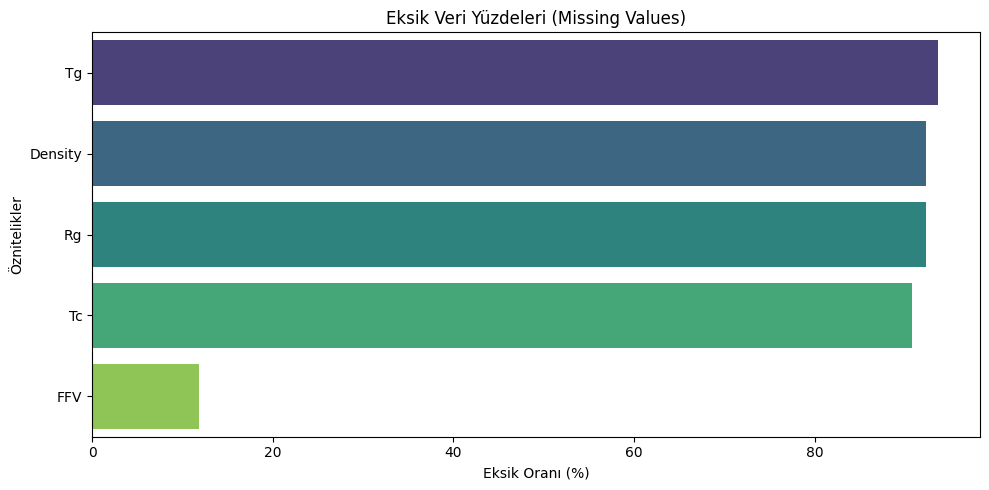

In [18]:
import sys
# Eski modül hafızasını temizle
if 'src.utils' in sys.modules:
    del sys.modules['src.utils']

from src.utils import analyze_missing_values

# Orijinal verideki eksiklikleri barplot ile çizdir
analyze_missing_values(train_df)

In [19]:
%%writefile src/models.py
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import numpy as np

def train_baseline_model(df, target_col='Tg'):
    """
    SMILES metin uzunluğunu basit bir öznitelik (feature) olarak kullanarak
    belirtilen hedef değişken için temel bir makine öğrenmesi modeli eğitir.
    """
    print(f"--- Baseline Model Eğitimi (Hedef: {target_col}) ---")

    # 1. Özellik Çıkarımı (Feature Engineering): SMILES string uzunluğunu hesapla
    X = df['SMILES'].apply(len).values.reshape(-1, 1)

    # Hedef değişkeni belirle
    y = df[target_col].values

    # 2. Veriyi Eğitim (%80) ve Test (%20) olarak ikiye böl
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 3. Temel Modeli Tanımla ve Eğit (Hızlı çalışması için 10 ağaç kullanıyoruz)
    model = RandomForestRegressor(n_estimators=10, random_state=42)
    model.fit(X_train, y_train)

    # 4. Test seti üzerinde tahmin yap ve hatayı (RMSE) ölç
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"Model başarıyla eğitildi!")
    print(f"Test Seti Hata Oranı (RMSE): {rmse:.4f}")

    return model

Writing src/models.py


In [20]:
import sys
# Modül hafızasını temizle
if 'src.models' in sys.modules:
    del sys.modules['src.models']

# Modeli projeye dahil et
from src.models import train_baseline_model

# Temizlenmiş verimizi kullanarak 'Tg' (Glass Transition Temp) hedefini tahmin eden modeli eğit
baseline_model = train_baseline_model(train_df_clean, target_col='Tg')

--- Baseline Model Eğitimi (Hedef: Tg) ---
Model başarıyla eğitildi!
Test Seti Hata Oranı (RMSE): 24.4173
